# Diniz Ch.7 — Error-feedback lattice RLS equalization

Example 7.2：26 feedforward taps、delay=18

## 1. Setup

In [1]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Data and model

In [2]:
n_samples, seed = 100, 1
h = 0.1 * 0.5**np.arange(9)
batch = data.equalization(n_samples, rng=np.random.default_rng(seed), h=h, decision_delay=18, noise_var=10**-2.5,
                          symbol_kind="bpsk", prefix=60)
model = ae.ErrorFeedbackLatticeRlsEq(n_ff=26, n_fb=0, lam=0.99, epsilon=0.1, verify_direct=True, dtype=np.complex128)

## 3. Training

In [3]:
result = training.run(model, batch, name="Lattice RLS equalizer")
results = {result.name: result}
cascade = np.convolve(h, np.conj(result.w_final))

## 4. Physical error and reconstructed equalizer

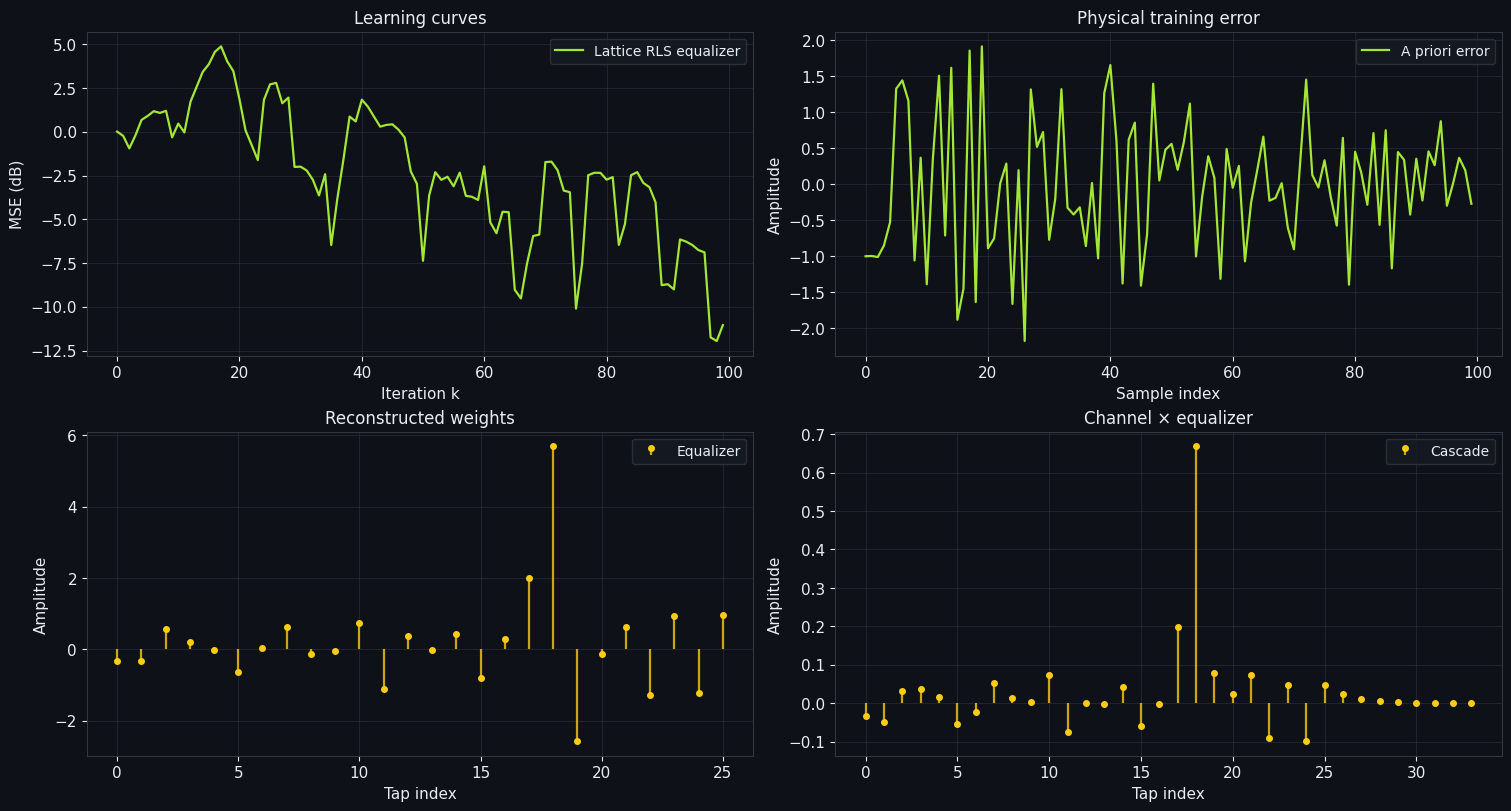

Model                                  Tail MSE     Tail MSD  Update rate
Lattice RLS equalizer                   0.36431            —            —


In [4]:
fig, grid = plot.axes(rows=2, cols=2)
plot.learning(results, ax=grid[0, 0], window=5)
plot.lines({"A priori error": result.e.real}, ax=grid[0, 1], title="Physical training error")
plot.stem({"Equalizer": result.w_final.real}, ax=grid[1, 0], title="Reconstructed weights")
plot.stem({"Cascade": cascade.real}, ax=grid[1, 1], title="Channel × equalizer")
plot.show(fig)
training.summary(results, tail=30)